**Практическая работа №5**

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
sns.set(style="whitegrid")

In [22]:
df = pd.read_csv('titanic.csv')

In [24]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']

In [25]:
target = 'Survived'

data = df[features + [target]].copy()

In [26]:
print("Пропущенные значения до обработки:")
print(data.isnull().sum())

Пропущенные значения до обработки:
Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64


In [27]:
data['Age'] = data['Age'].fillna(data['Age'].median())

print("Пропущенные значения после обработки:")
print(data.isnull().sum())

Пропущенные значения после обработки:
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


In [28]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

In [29]:
print("Столбцы таблицы:", list(data.columns))
print("\nТипы данных:")
print(data.dtypes)
print("\nПропущенные значения:", data.isnull().sum().sum())
print("\nРазмер таблицы:", data.shape)

Столбцы таблицы: ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']

Типы данных:
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

Пропущенные значения: 0

Размер таблицы: (891, 7)


In [30]:
print("Первые 5 строк подготовленной таблицы:")
print(data.head())

Первые 5 строк подготовленной таблицы:
   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0


In [31]:
corr_matrix = data.corr()

In [32]:
print("Корреляционная матрица:")
print(corr_matrix.round(2))

Корреляционная матрица:
          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


In [33]:
corr_matrix_rounded = corr_matrix.round(2)
print(corr_matrix_rounded)

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


In [34]:
survived_corr = corr_matrix['Survived'].drop('Survived')
print("Корреляция признаков с Survived:")
print(survived_corr.round(2))

Корреляция признаков с Survived:
Pclass   -0.34
Age      -0.06
Sex       0.54
Fare      0.26
SibSp    -0.04
Parch     0.08
Name: Survived, dtype: float64


In [35]:
most_positive = survived_corr.idxmax()
print(f"Наиболее сильная положительная корреляция: {most_positive} ({survived_corr[most_positive]:.2f})")

Наиболее сильная положительная корреляция: Sex (0.54)


In [36]:
most_negative = survived_corr.idxmin()
print(f"Наиболее сильная отрицательная корреляция: {most_negative} ({survived_corr[most_negative]:.2f})")

Наиболее сильная отрицательная корреляция: Pclass (-0.34)


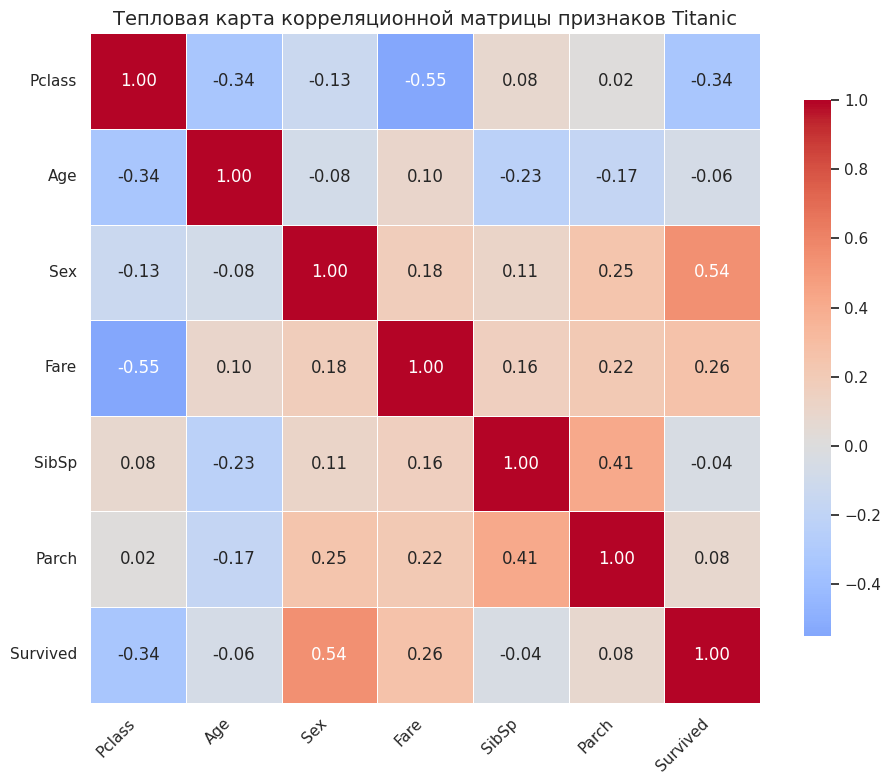

In [38]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Тепловая карта корреляционной матрицы признаков Titanic', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Ответы на вопросы по тепловой карте:**

1)Какую функцию библиотеки seaborn необходимо использовать?

-sns.heatmap()


2)Какие данные передать в эту функцию?

-Корреляционную матрицу corr_matrix (результат data.corr())


3)Какой параметр позволит вывести значения коэффициентов внутри ячеек?

-annot=True


4)Какой параметр отвечает за цветовую палитру?

-cmap='coolwarm'


5)Как задать размер графика?

-plt.figure(figsize=(10, 8)) перед вызовом sns.heatmap()

**Какие признаки могут быть наиболее полезны для предсказания Survived?**

Наиболее полезны Sex, Pclass и Fare. Пол и класс — сильнее всего связаны с выживанием: женщины и пассажиры 1-го класса выживали чаще. Остальные признаки (Age, SibSp, Parch) показали слабую линейную связь.

**Можно ли выбирать признаки только на основании корреляции?**

Нет. Корреляция Пирсона отражает только линейную связь, не учитывает взаимодействия признаков и нелинейные зависимости, а также не говорит о причинно-следственной связи. Корреляцию можно использовать как первичный ориентир, но окончательный отбор признаков следует проводить с помощью моделей машинного обучения и кросс-валидации.